In [2]:
import glob
import h5py
from tqdm import tqdm
import numpy as np
from matplotlib import pyplot as plt
import os

In [3]:
def read_files(glob_pattern, minyear=0, maxyear=9999, no_weights=False):
    files = glob.glob(glob_pattern)
    angles = []
    weights = []
    
    lats = np.arange(-89.0, 90.0, 1, dtype=np.float64)
    lons = np.arange(-180.0, 180.0, 1, dtype=np.float64)
    lat_grid, lon_grid = np.meshgrid(lats, lons, indexing="ij")
    
    for fpath in tqdm(files):
        year = int(os.path.basename(fpath)[:4])
        if year > maxyear:
            continue
        if year < minyear:
            continue

        hdf = h5py.File(fpath)
        
        angles.append(hdf['angles_deg'][:])

        if not no_weights:
            weights.append(np.cos(np.deg2rad(lat_grid)))
            
        hdf.close()

    if no_weights:
        return np.array(angles).flatten()
    
    return np.array(angles).flatten(), np.array(weights).flatten()

In [4]:
angles_samples = read_files('../data/validation/angle_samples/*.hdf5', no_weights=True)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2748/2748 [00:03<00:00, 781.16it/s]


In [5]:
angles_testdata, weights_testdata = read_files('../data/validation/angle_testdata/*.hdf5')

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5496/5496 [00:12<00:00, 436.39it/s]


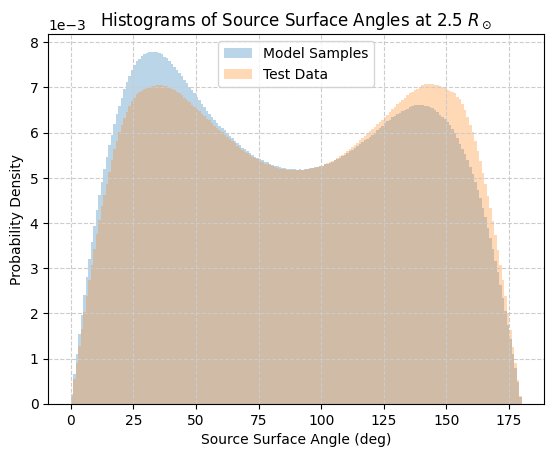

In [6]:
bins = np.arange(0, 181, 1)

plt.hist(angles_samples, bins=bins, weights=weights_testdata[:angles_samples.size], label='Model Samples', density=True, alpha=0.3)
plt.hist(angles_testdata, bins=bins, weights=weights_testdata, label='Test Data', density=True, alpha=0.3)

plt.legend()
plt.ylabel('Probability Density')
plt.xlabel('Source Surface Angle (deg)')
plt.title(r'Histograms of Source Surface Angles at 2.5 $R_\odot$')
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.grid(linestyle='dashed', color='#ccc')
plt.savefig('../plots/paper/source_surf_angles_hist.png', dpi=300)

In [7]:
def weighted_std(x, weights, axis=None):
    x = np.asarray(x, dtype=float)
    w = np.asarray(weights, dtype=float)
    mean = np.average(x, weights=w, axis=axis)
    # keep dims so broadcasting works for the axis case
    if axis is not None:
        mean_b = np.expand_dims(mean, axis)
    else:
        mean_b = mean
    var = np.average((x - mean_b)**2, weights=w, axis=axis)
    return np.sqrt(var)

In [11]:
print('Samples')
print('---------')

w = weights_testdata[:angles_samples.size]
print('Mean %.1f' % np.average(angles_samples, weights=w))
print('STD %.1f' % weighted_std(angles_samples, weights=w))
print()

print('Test Data')
print('---------')
w = weights_testdata
print('Mean %.1f' % np.average(angles_testdata, weights=w))
print('STD %.1f' % weighted_std(angles_testdata, weights=w))
print()

Samples
---------
Mean 86.4
STD 48.1

Test Data
---------
Mean 90.0
STD 48.3

